In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error



In [13]:
df = pd.read_csv("Sample - Superstore.csv", encoding="cp1252")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [14]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nFirst five records:")
display(df.head())

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


First five records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [15]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Sales"] = pd.to_numeric(
    df["Sales"], errors="coerce"
)

df = df.dropna(subset=["Order Date", "Sales"])
df = df.drop_duplicates().copy()
df = df.sort_values("Order Date")

print("Missing values after cleaning:")
display(df[["Order Date", "Sales"]].isnull().sum())

print("Date range:", df["Order Date"].min(),
      "to", df["Order Date"].max())
print("Total records:", len(df))

Missing values after cleaning:


Order Date    0
Sales         0
dtype: int64

Date range: 2014-01-03 00:00:00 to 2017-12-30 00:00:00
Total records: 9994


In [16]:
monthly_sales = (
    df.set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Date", "Sales"]

display(monthly_sales.head())
print("Number of months:", len(monthly_sales))

,Date,Sales
0,2014-01-01,14236.895
1,2014-02-01,4519.892
2,2014-03-01,55691.009
3,2014-04-01,28295.345
4,2014-05-01,23648.287


Number of months: 48


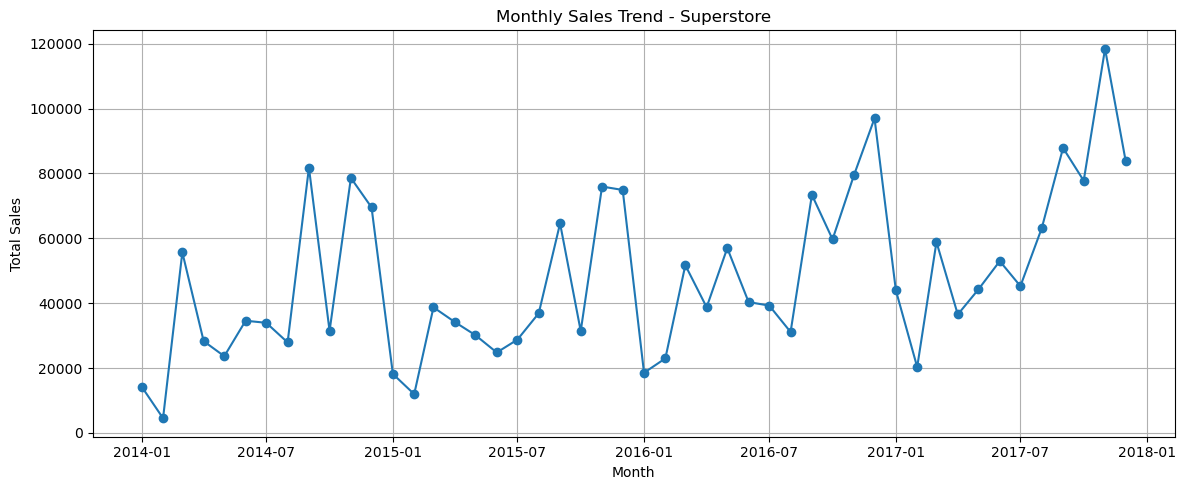

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Date"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend - Superstore")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:

data = monthly_sales.copy()

data["Year"] = data["Date"].dt.year
data["Month"] = data["Date"].dt.month

data["Lag_1"] = data["Sales"].shift(1)
data["Lag_2"] = data["Sales"].shift(2)
data["Lag_3"] = data["Sales"].shift(3)


data = data.dropna().reset_index(drop=True)

print("Data prepared successfully!")
display(data.head())

Data prepared successfully!


,Date,Sales,Year,Month,Lag_1,Lag_2,Lag_3
0,2014-04-01,28295.3450,2014,4,55691.0090,4519.8920,14236.895
1,2014-05-01,23648.2870,2014,5,28295.3450,55691.0090,4519.892
2,2014-06-01,34595.1276,2014,6,23648.2870,28295.3450,55691.009
3,2014-07-01,33946.3930,2014,7,34595.1276,23648.2870,28295.345
4,2014-08-01,27909.4685,2014,8,33946.3930,34595.1276,23648.287


In [20]:
features = ["Year", "Month", "Lag_1", "Lag_2", "Lag_3"]

split_index = int(len(data) * 0.8)

train_data = data.iloc[:split_index]
test_data = data.iloc[split_index:]

X_train = train_data[features]
y_train = train_data["Sales"]

X_test = test_data[features]
y_test = test_data["Sales"]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (36, 5)
Testing data: (9, 5)


In [21]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [22]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Model Evaluation Results")
print("------------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

Model Evaluation Results
------------------------
MAE:  14458.66
RMSE: 19320.03


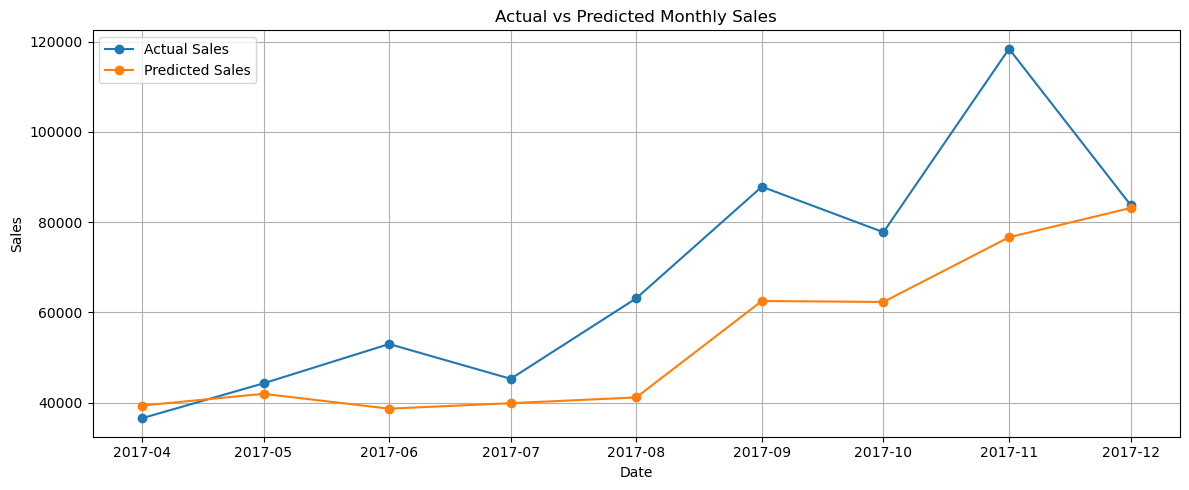

,Date,Actual Sales,Predicted Sales
0,2017-04-01,36521.5361,39328.681900
1,2017-05-01,44261.1102,41939.410239
2,2017-06-01,52981.7257,38649.094226
3,2017-07-01,45264.4160,39858.864944
4,2017-08-01,63120.8880,41145.746149
5,2017-09-01,87866.6520,62520.501983
6,2017-10-01,77776.9232,62311.654758
7,2017-11-01,118447.8250,76656.893393
8,2017-12-01,83829.3188,83145.884723


In [23]:
results = pd.DataFrame({
    "Date": test_data["Date"].values,
    "Actual Sales": y_test.values,
    "Predicted Sales": predictions
})

plt.figure(figsize=(12, 5))

plt.plot(
    results["Date"],
    results["Actual Sales"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    results["Date"],
    results["Predicted Sales"],
    marker="o",
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Monthly Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

display(results)

In [24]:
history = monthly_sales["Sales"].tolist()
last_date = monthly_sales["Date"].max()

future_rows = []

for i in range(1, 4):
    next_date = last_date + pd.DateOffset(months=i)

    row = pd.DataFrame([{
        "Year": next_date.year,
        "Month": next_date.month,
        "Lag_1": history[-1],
        "Lag_2": history[-2],
        "Lag_3": history[-3]
    }])

    predicted_sales = max(
        0, model.predict(row[features])[0]
    )

    future_rows.append({
        "Date": next_date,
        "Predicted Sales": round(predicted_sales, 2)
    })

    history.append(predicted_sales)

future_forecast = pd.DataFrame(future_rows)

display(future_forecast)

,Date,Predicted Sales
0,2018-01-01,26308.36
1,2018-02-01,33608.21
2,2018-03-01,42733.86


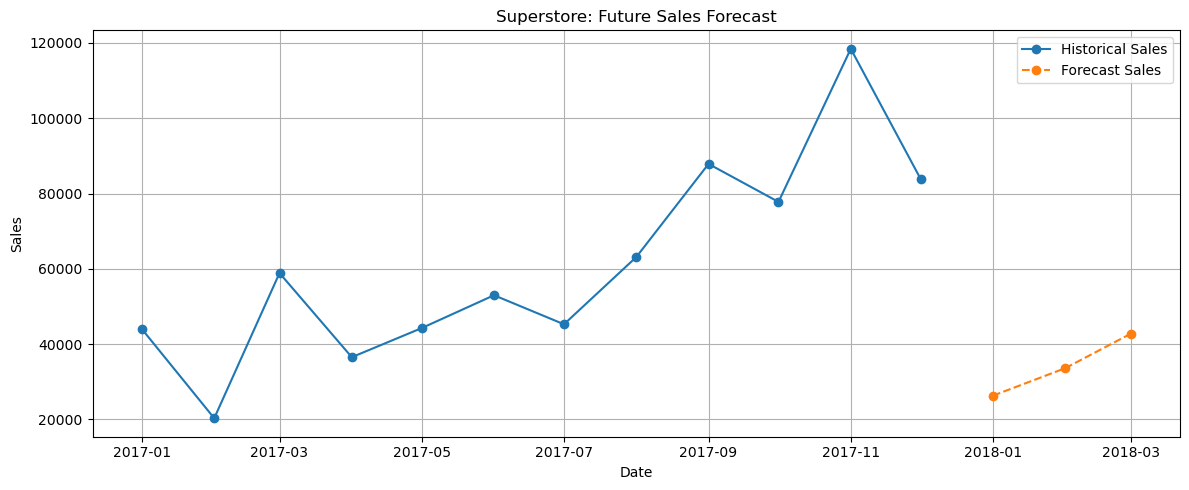

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Date"].tail(12),
    monthly_sales["Sales"].tail(12),
    marker="o",
    label="Historical Sales"
)

plt.plot(
    future_forecast["Date"],
    future_forecast["Predicted Sales"],
    marker="o",
    linestyle="--",
    label="Forecast Sales"
)

plt.title("Superstore: Future Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [26]:
print("SALES FORECAST BUSINESS REPORT")
print("=" * 35)

print("Total forecast sales:",
      round(future_forecast["Predicted Sales"].sum(), 2))

print("Average forecast monthly sales:",
      round(future_forecast["Predicted Sales"].mean(), 2))

best_month = future_forecast.loc[
    future_forecast["Predicted Sales"].idxmax()
]

print("Highest predicted month:",
      best_month["Date"].strftime("%B %Y"))

print("Highest predicted sales:",
      best_month["Predicted Sales"])

SALES FORECAST BUSINESS REPORT
Total forecast sales: 102650.43
Average forecast monthly sales: 34216.81
Highest predicted month: March 2018
Highest predicted sales: 42733.86
